# Лабораторная работа №1
## Анализ и прогнозирование временных рядов на примере розничных продаж

**Исходные данные:** `data/retail_sales_mock_data.csv`, 48 месяцев, январь 2020 - декабрь 2023.
`SalesAmount` - продажи; `Promotion` — индикатор акции;
`HolidayMonth` - индикатор праздничного месяца, в этом файле декабря.
Валюта в задании не указана, поэтому используем условные денежные единицы.

Работа состоит из пяти этапов, каждый заканчивается аналитическими выводами:

1. Загрузка, проверка данных и EDA.
2. Классическая декомпозиция, FFT и вейвлет-анализ.
3. Подбор параметров и обучение ARIMA/SARIMAX.
4. Метрики, информационные критерии и диагностика остатков.
5. Проверка горизонта, прогноз будущих продаж и итоговая интерпретация.

Установка зависимостей:

```bash
uv sync
```

In [29]:
from pathlib import Path
from itertools import product
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pywt
import statsmodels.api as sm

from IPython.display import display, Markdown
from scipy import stats
from scipy.fft import fft, fftfreq, ifft
from scipy.signal import detrend
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning, EstimationWarning
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_breuschpagan

sns.set_theme(style='whitegrid', font='DejaVu Sans')
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

ROOT = Path.cwd()

## 1. Загрузка, проверка данных и EDA

До анализа фиксируем хронологическое разбиение:

- train: 2020–2021, 24 месяца, оценка параметров кандидатов;
- validation: 2022, 12 месяцев, выбор конфигурации и горизонта;
- test: 2023, 12 месяцев, итоговая проверка после фиксации выбора.

EDA, декомпозиция и тесты стационарности ниже используют только train.
После выбора модели её коэффициенты переоцениваются на train + validation, порядки модели остаются зафиксированными. На начальном обучении два сезонных цикла, что ограничивает надёжность оценки сезонности.

In [30]:
raw = pd.read_csv(ROOT / 'data/retail_sales_mock_data.csv', parse_dates=['Date'])

df = raw.sort_values('Date').set_index('Date')
expected_dates = pd.date_range(df.index.min(), df.index.max(), freq='MS')
missing_dates = expected_dates.difference(df.index)
df = df.asfreq('MS')  # Явно задаём шаг(начало каждого месяца)

train = df.loc['2020':'2021'].copy()
validation = df.loc['2022'].copy()
test = df.loc['2023'].copy()
y_eda = train['SalesAmount'].astype(float)

quality = pd.DataFrame({
    'Показатель': ['Наблюдений', 'Начало', 'Конец', 'Пропущенных месяцев',
                   'Пропущенных значений', 'Повторяющихся дат', 'Частота'],
    'Значение': [len(df), str(df.index.min().date()), str(df.index.max().date()),
                 len(missing_dates), int(df.isna().sum().sum()),
                 int(raw['Date'].duplicated().sum()), df.index.freqstr],
})
display(quality)
display(train.head())
display(y_eda.describe().to_frame('SalesAmount: train'))

# используется для маркировки
q1, q3 = y_eda.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = y_eda[(y_eda < q1 - 1.5 * iqr) | (y_eda > q3 + 1.5 * iqr)]
print(f'Кандидатов в выбросы по IQR на train: {len(iqr_outliers)}. Значения не заменяем.')

,Показатель,Значение
0,Наблюдений,48
1,Начало,2020-01-01
2,Конец,2023-12-01
3,Пропущенных месяцев,0
4,Пропущенных значений,0
5,Повторяющихся дат,0
6,Частота,MS


,SalesAmount,Promotion,HolidayMonth
Date,,,
2020-01-01,12248,0,0
2020-02-01,13011,0,0
2020-03-01,12722,0,0
2020-04-01,14030,1,0
2020-05-01,7783,0,0


,SalesAmount: train
count,24.000
mean,"11,255.125"
std,"2,039.166"
min,"7,783.000"
25%,"9,929.250"
50%,"10,885.500"
75%,"12,722.500"
max,"14,696.000"


Кандидатов в выбросы по IQR на train: 0. Значения не заменяем.


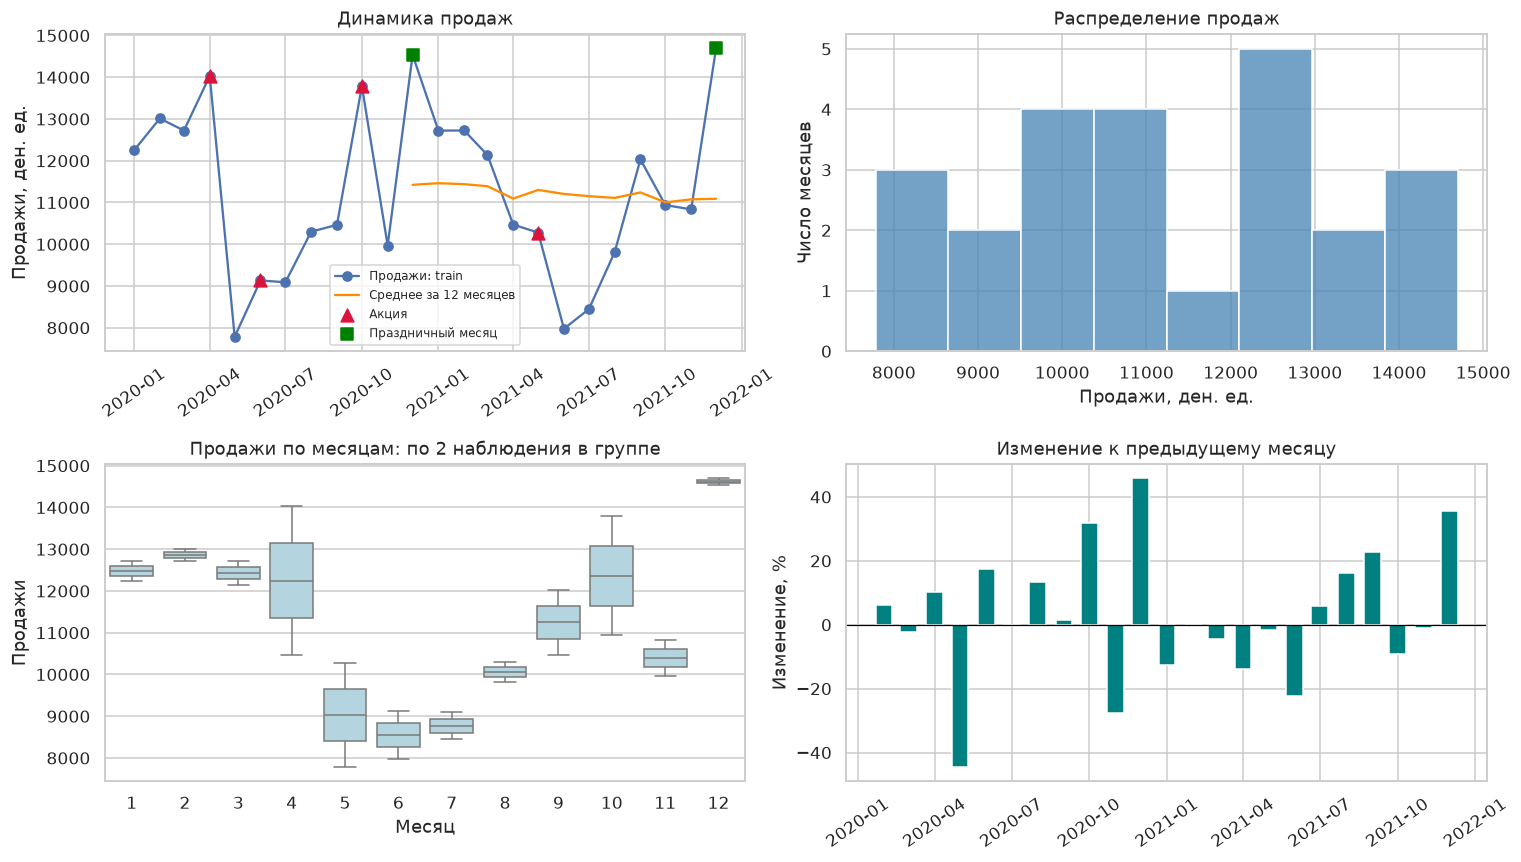

In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes[0, 0].plot(y_eda.index, y_eda, marker='o', label='Продажи: train')
axes[0, 0].plot(y_eda.rolling(12).mean(), color='darkorange', label='Среднее за 12 месяцев')
for column, color, marker, label in [
    ('Promotion', 'crimson', '^', 'Акция'),
    ('HolidayMonth', 'green', 's', 'Праздничный месяц'),
]:
    mask = train[column].eq(1)
    axes[0, 0].scatter(train.index[mask], y_eda[mask], color=color,
                       marker=marker, s=70, label=label, zorder=4)
axes[0, 0].set(title='Динамика продаж', ylabel='Продажи, ден. ед.')
axes[0, 0].legend(fontsize=8)

sns.histplot(y_eda, bins=8, ax=axes[0, 1], color='steelblue')
axes[0, 1].set(title='Распределение продаж', xlabel='Продажи, ден. ед.', ylabel='Число месяцев')

eda_frame = train.assign(Month=train.index.month, Year=train.index.year)
sns.boxplot(data=eda_frame, x='Month', y='SalesAmount', color='lightblue', ax=axes[1, 0])
axes[1, 0].set(title='Продажи по месяцам: по 2 наблюдения в группе', xlabel='Месяц', ylabel='Продажи')

axes[1, 1].bar(y_eda.index, y_eda.pct_change() * 100, width=20, color='teal')
axes[1, 1].axhline(0, color='black', linewidth=0.8)
axes[1, 1].set(title='Изменение к предыдущему месяцу', ylabel='Изменение, %')
for ax in [axes[0, 0], axes[1, 1]]:
    ax.tick_params(axis='x', rotation=35)
fig.tight_layout()
plt.show()

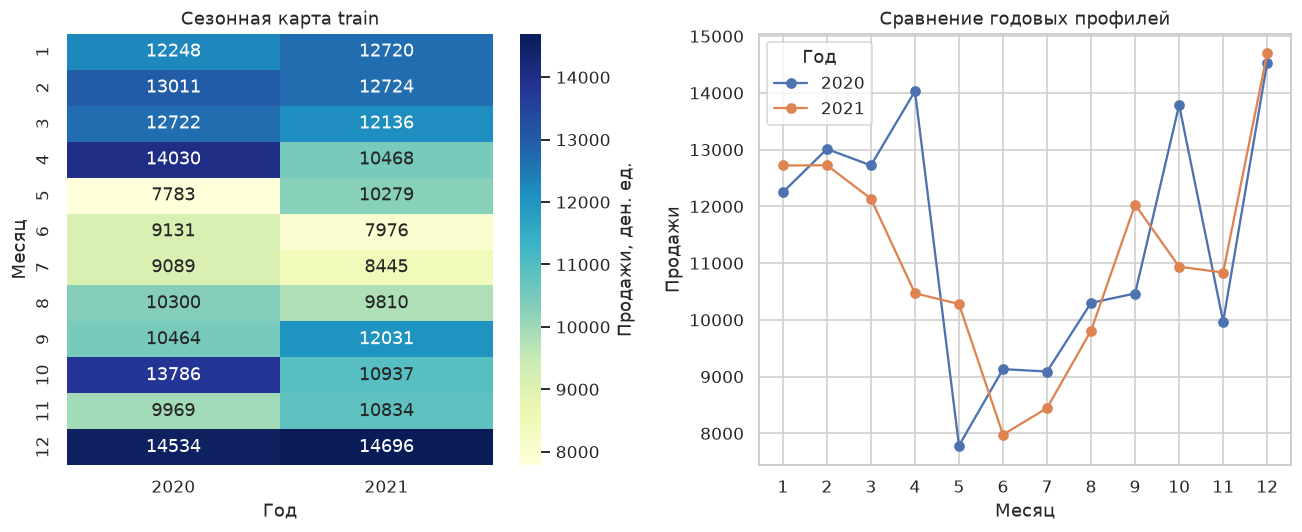

,count,mean,std
Promotion,,,
0,20,"11,144.850","1,997.701"
1,4,"11,806.500","2,473.454"


,mean,std,min,max
Date,,,,
2020,"11,422.250","2,240.001",7783,14534
2021,"11,088.000","1,901.545",7976,14696


In [32]:
month_year = pd.pivot_table(eda_frame, values='SalesAmount', index='Month', columns='Year')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(month_year, annot=True, fmt='.0f', cmap='YlGnBu', ax=axes[0],
            cbar_kws={'label': 'Продажи, ден. ед.'})
axes[0].set(title='Сезонная карта train', xlabel='Год', ylabel='Месяц')
for year, group in eda_frame.groupby('Year'):
    axes[1].plot(group['Month'], group['SalesAmount'], marker='o', label=str(year))
axes[1].set(title='Сравнение годовых профилей', xlabel='Месяц', ylabel='Продажи', xticks=range(1, 13))
axes[1].legend(title='Год')
fig.tight_layout()
plt.show()

group_summary = train.groupby('Promotion')['SalesAmount'].agg(['count', 'mean', 'std'])
display(group_summary)
display(train.groupby(train.index.year)['SalesAmount'].agg(['mean', 'std', 'min', 'max']))

In [33]:
month_means = y_eda.groupby(y_eda.index.month).mean()
peak_month, low_month = int(month_means.idxmax()), int(month_means.idxmin())
display(Markdown(f"""
### Выводы по этапу 1

В файле **{len(df)}** последовательных месячных наблюдений без пропусков и повторяющихся дат.
Средние продажи на train — **{y_eda.mean():,.0f}** ден. ед.,
минимум — **{y_eda.min():,.0f}**, максимум — **{y_eda.max():,.0f}**.
Максимум среднего годового профиля приходится на месяц **{peak_month}**,
минимум — на месяц **{low_month}**. Проверим сезонный период **12 месяцев**.

Пики могут быть связаны с акциями и декабрём, поэтому наблюдения не удаляем.
Различие средних при `Promotion=0/1` само по себе не доказывает причинный эффект акций.
"""))


### Выводы по этапу 1

В файле **48** последовательных месячных наблюдений без пропусков и повторяющихся дат.
Средние продажи на train — **11,255** ден. ед.,
минимум — **7,783**, максимум — **14,696**.
Максимум среднего годового профиля приходится на месяц **12**,
минимум — на месяц **6**. Проверим сезонный период **12 месяцев**.

Пики могут быть связаны с акциями и декабрём, поэтому наблюдения не удаляем.
Различие средних при `Promotion=0/1` само по себе не доказывает причинный эффект акций.


## 2. Декомпозиция и анализ периодичности

Сравниваем три подхода:

1. **Классический:** аддитивная, мультипликативная и STL-декомпозиция с периодом 12.
2. **FFT:** удаление линейного тренда, поиск частот и восстановление годовой гармоники.
3. **Вейвлеты:** CWT Морле для локализации периодичности во времени.

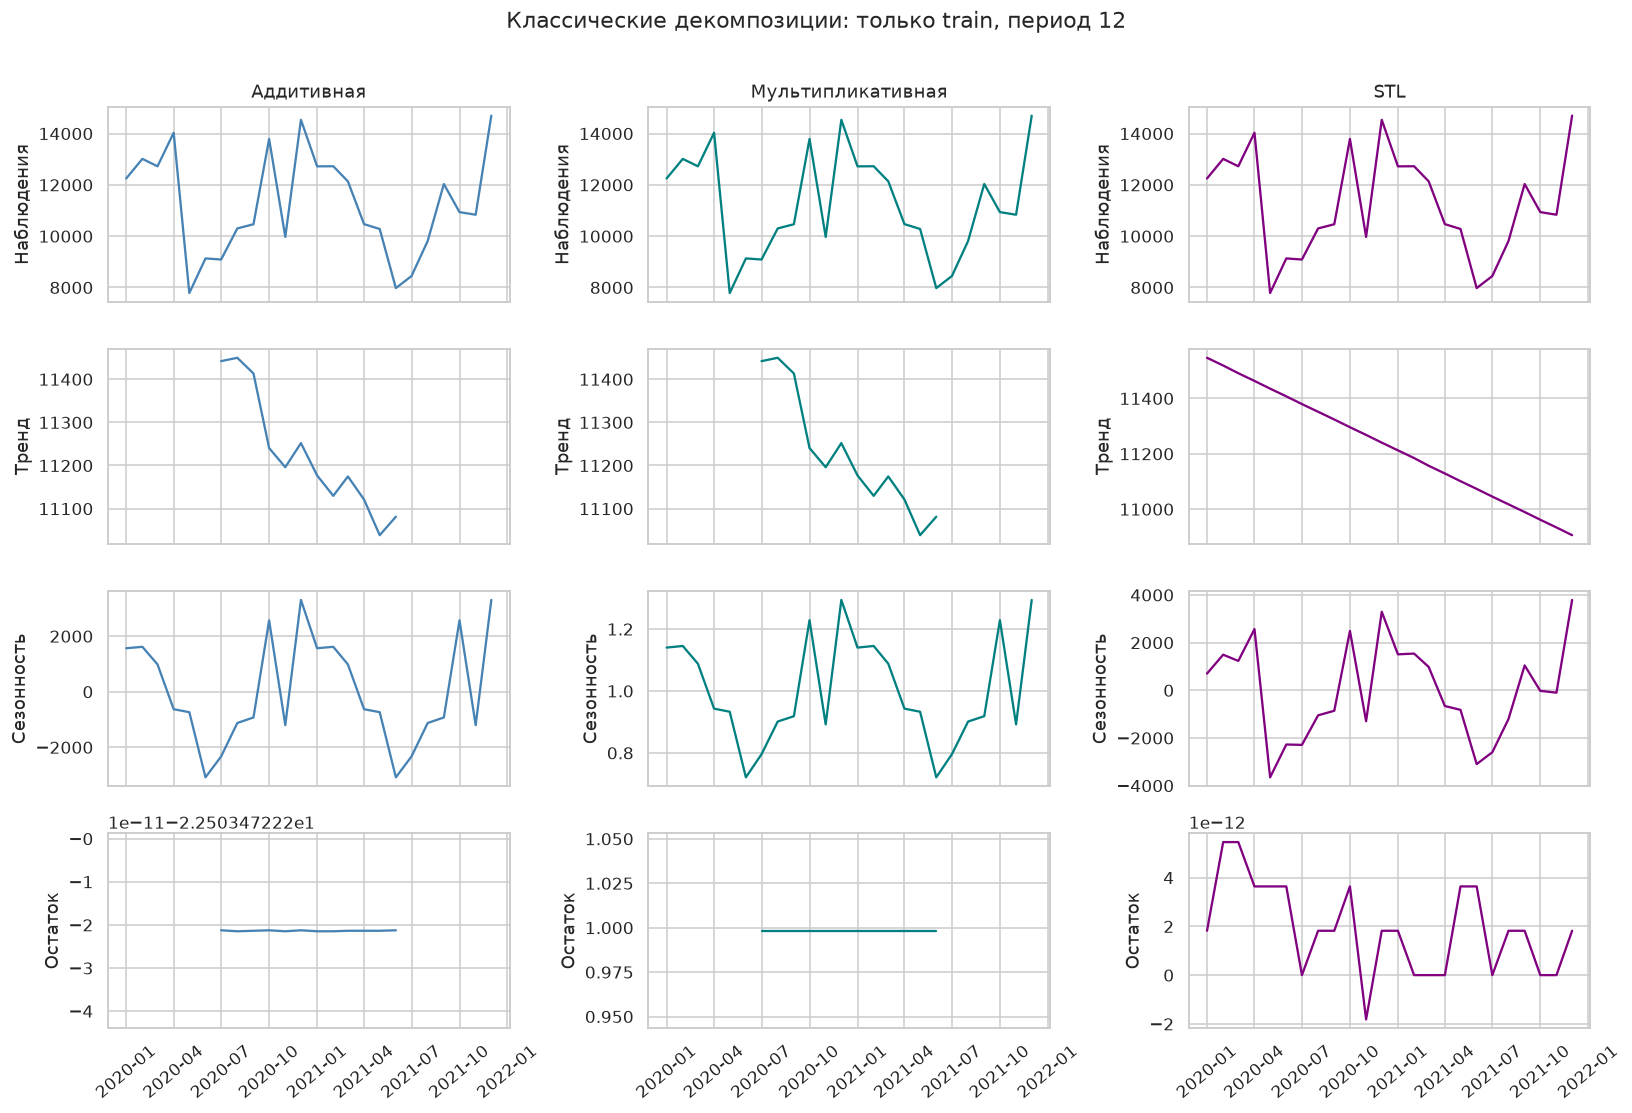

,Доступно остатков,RMSE на общем центральном отрезке
Метод,,
Аддитивная,12,22.503
Мультипликативная,12,19.965
STL,24,0.000


In [34]:
additive = seasonal_decompose(y_eda, model='additive', period=12)
multiplicative = seasonal_decompose(y_eda, model='multiplicative', period=12)
stl_result = STL(y_eda, period=12, seasonal=13, robust=True).fit()

fig, axes = plt.subplots(4, 3, figsize=(15, 10), sharex=True)
decompositions = {'Аддитивная': additive, 'Мультипликативная': multiplicative, 'STL': stl_result}
for j, (name, result) in enumerate(decompositions.items()):
    for i, (component, label) in enumerate([
        (result.observed, 'Наблюдения'), (result.trend, 'Тренд'),
        (result.seasonal, 'Сезонность'), (result.resid, 'Остаток'),
    ]):
        axes[i, j].plot(component.index, component, color=['steelblue', 'teal', 'purple'][j])
        axes[i, j].set_ylabel(label)
    axes[0, j].set_title(name)
    axes[-1, j].tick_params(axis='x', rotation=40)
fig.suptitle('Классические декомпозиции: только train, период 12', y=1.01)
fig.tight_layout()
plt.show()

# Для сравнения возвращаем остатки мультипликативной модели в денежный масштаб
decomposition_residuals = {
    'Аддитивная': additive.resid,
    'Мультипликативная': y_eda - multiplicative.trend * multiplicative.seasonal,
    'STL': stl_result.resid,
}
common_index = additive.resid.dropna().index
decomposition_table = pd.DataFrame([
    {'Метод': name, 'Доступно остатков': int(residual.notna().sum()),
     'RMSE на общем центральном отрезке': np.sqrt(np.mean(residual.loc[common_index] ** 2))}
    for name, residual in decomposition_residuals.items()
]).set_index('Метод')
display(decomposition_table)

Классическая декомпозиция оставляет по 6 неопределённых значений с каждого края.
Остатки сравниваются на общем центральном отрезке в денежных единицах.
Мультипликативная сезонность — множитель около 1, аддитивная — денежная поправка.
Малая ошибка разложения STL не означает высокую точность прогноза.

,"Частота, циклов/месяц","Период, месяцев","Амплитуда, ден. ед."
1,0.083,12.000,"2,128.795"
10,0.458,2.182,766.218
6,0.292,3.429,720.452
7,0.333,3.000,687.000
3,0.167,6.000,633.987


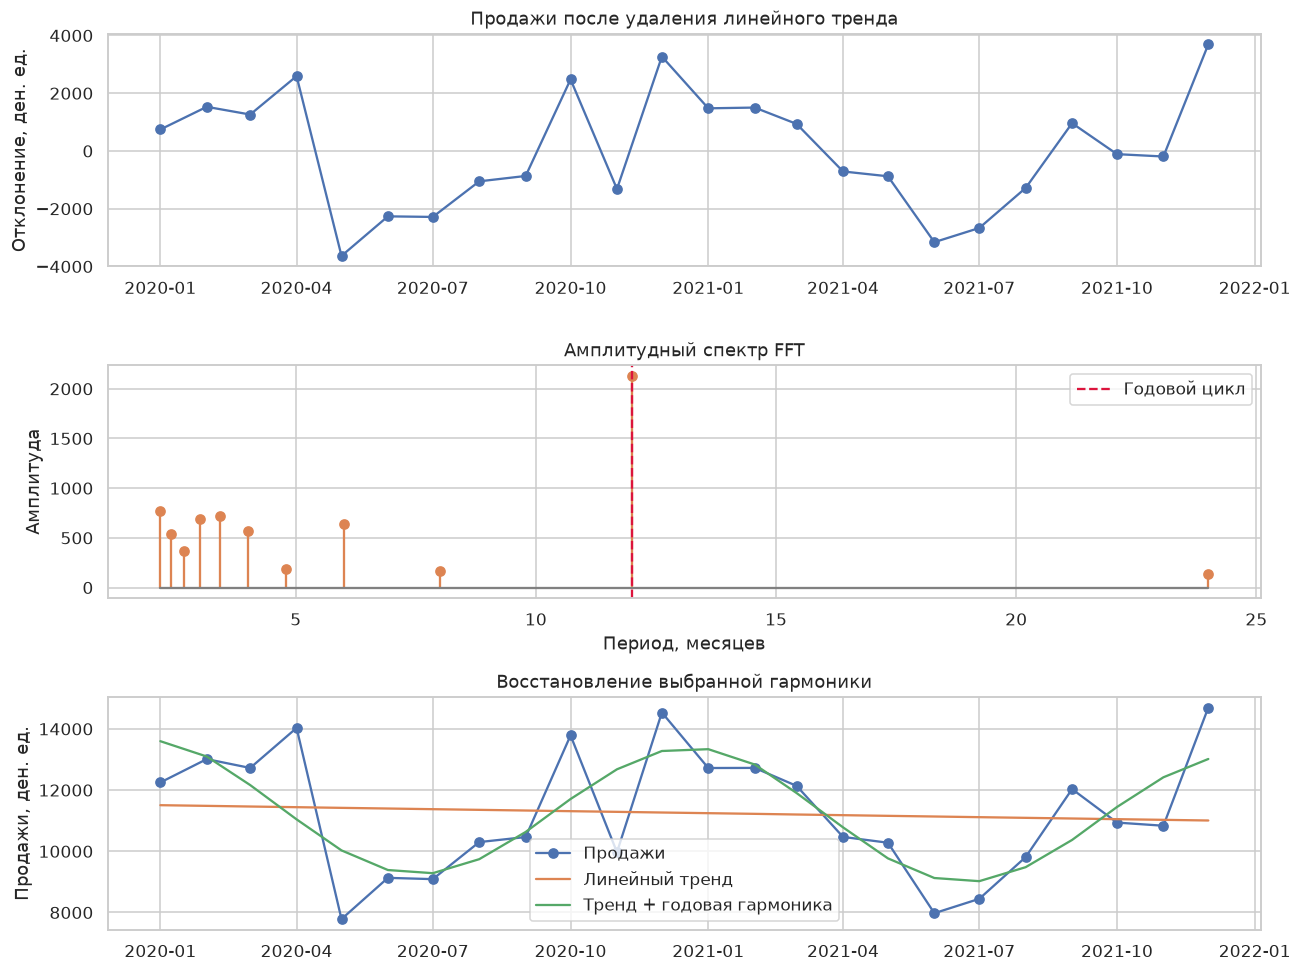

Доля энергии детрендированного ряда в годовой паре FFT: 57.2%
Частотный шаг: 1/24 = 0.0417 цикла/месяц. Пики не являются тестом значимости.


In [35]:
sales_detrended = detrend(y_eda.to_numpy(), type='linear')
linear_trend = y_eda.to_numpy() - sales_detrended
n = len(sales_detrended)
fft_values = fft(sales_detrended)
frequencies = fftfreq(n, d=1)  # Частота в циклах за месяц
positive = frequencies > 0
freq_pos = frequencies[positive]
periods_fft = 1 / freq_pos
amplitudes = 2 * np.abs(fft_values[positive]) / n
fft_peaks = pd.DataFrame({
    'Частота, циклов/месяц': freq_pos,
    'Период, месяцев': periods_fft,
    'Амплитуда, ден. ед.': amplitudes,
}).sort_values('Амплитуда, ден. ед.', ascending=False)
display(fft_peaks.head(5))

# Оставляем сопряжённую пару частот годового цикла и выполняем обратный FFT
annual_bin = int(np.argmin(np.abs(freq_pos - 1 / 12)))
annual_frequency = freq_pos[annual_bin]
annual_mask = np.isclose(np.abs(frequencies), annual_frequency)
annual_coefficients = np.where(annual_mask, fft_values, 0)
annual_component = ifft(annual_coefficients).real
fft_reconstruction = linear_trend + annual_component

fig, axes = plt.subplots(3, 1, figsize=(12, 9))
axes[0].plot(y_eda.index, sales_detrended, marker='o')
axes[0].set(title='Продажи после удаления линейного тренда', ylabel='Отклонение, ден. ед.')
axes[1].stem(periods_fft, amplitudes, linefmt='C1-', markerfmt='C1o', basefmt='gray')
axes[1].axvline(12, color='crimson', linestyle='--', label='Годовой цикл')
axes[1].set(title='Амплитудный спектр FFT', xlabel='Период, месяцев', ylabel='Амплитуда')
axes[1].legend()
axes[2].plot(y_eda.index, y_eda, marker='o', label='Продажи')
axes[2].plot(y_eda.index, linear_trend, label='Линейный тренд')
axes[2].plot(y_eda.index, fft_reconstruction, label='Тренд + годовая гармоника')
axes[2].set(title='Восстановление выбранной гармоники', ylabel='Продажи, ден. ед.')
axes[2].legend()
fig.tight_layout()
plt.show()

annual_energy_share = np.sum(np.abs(fft_values[annual_mask]) ** 2) / np.sum(np.abs(fft_values) ** 2)
print(f'Доля энергии детрендированного ряда в годовой паре FFT: {annual_energy_share:.1%}')
print(f'Частотный шаг: 1/{n} = {1/n:.4f} цикла/месяц. Пики не являются тестом значимости.')

FFT показывает амплитуду; для расчёта доли энергии используются квадраты модулей коэффициентов.
Спектр характеризует ряд целиком и не показывает время появления цикла.

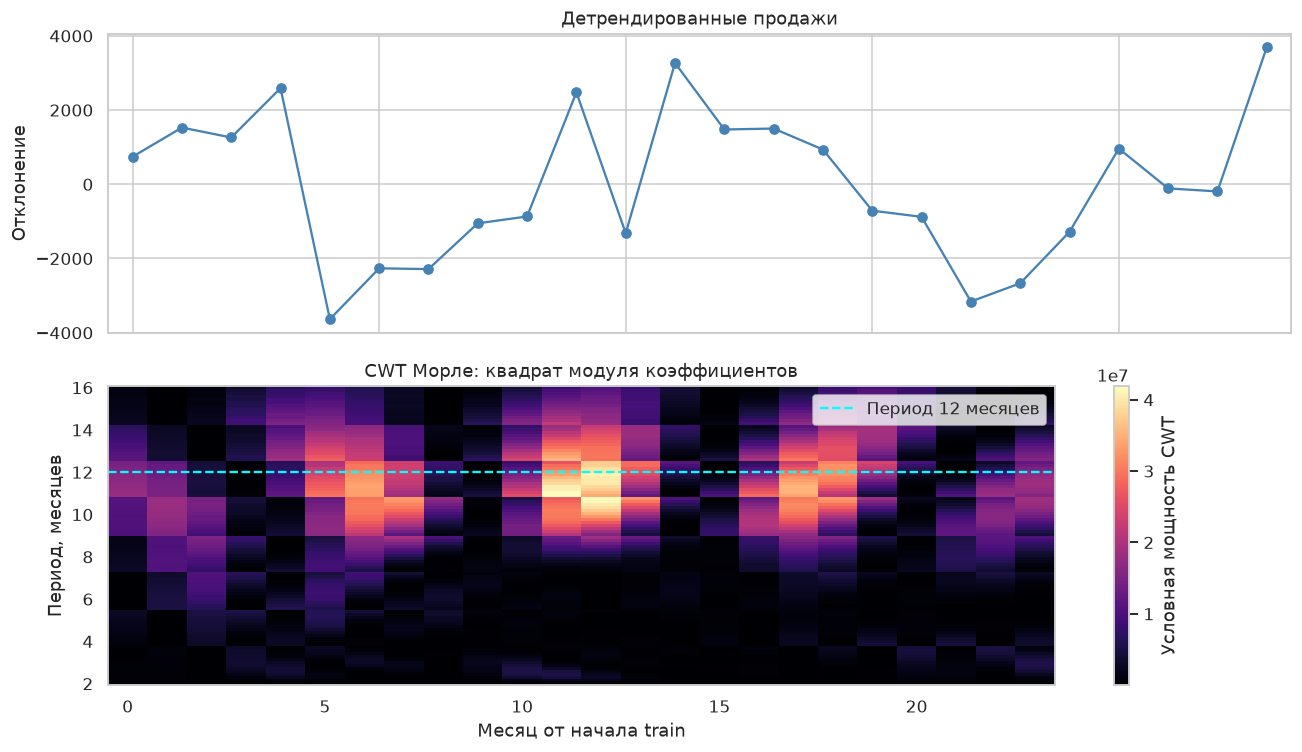

In [36]:
# Удаление тренда позволяет рассматривать колебания вокруг него
wavelet = 'morl'
target_periods = np.linspace(2, 16, 100)
scales = pywt.central_frequency(wavelet) * target_periods
coefficients, wavelet_frequencies = pywt.cwt(
    sales_detrended, scales, wavelet, sampling_period=1,
)
periods_wavelet = 1 / wavelet_frequencies
wavelet_power = np.abs(coefficients) ** 2

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
t = np.arange(n)
axes[0].plot(t, sales_detrended, marker='o', color='steelblue')
axes[0].set(title='Детрендированные продажи', ylabel='Отклонение')
im = axes[1].pcolormesh(t, periods_wavelet, wavelet_power, shading='auto', cmap='magma')
axes[1].axhline(12, color='cyan', linestyle='--', label='Период 12 месяцев')
axes[1].set(title='CWT Морле: квадрат модуля коэффициентов',
            xlabel='Месяц от начала train', ylabel='Период, месяцев')
axes[1].legend(loc='upper right')
fig.colorbar(im, ax=axes[1], label='Условная мощность CWT')
fig.tight_layout()
plt.show()

У годовой компоненты CWT сильны краевые эффекты. Колебания реального вейвлета Морле
также зависят от фазы: тёмные участки карты не обязательно означают исчезновение цикла.

| Подход | Результат | Преимущество | Ограничение |
|---|---|---|---|
| Аддитивная | Тренд, годовая поправка, остаток | Понятный денежный масштаб | Фиксированная сезонность; неопределённые края |
| Мультипликативная | Тренд и относительная сезонность | Подходит при росте амплитуды вместе с уровнем | Нужны положительные значения |
| STL | Гибкие тренд и сезонность | Робастность к отдельным пикам | Гибкость может давать слишком малые остатки |
| FFT | Глобальные частоты и годовая гармоника | Явно показывает период | Нет локализации во времени; спектральная утечка |
| CWT Морле | Распределение периодичности во времени | Локализация колебаний | Выбор масштабов и краевые эффекты |

In [37]:
dominant_fft_period = float(fft_peaks.iloc[0]['Период, месяцев'])
display(Markdown(f"""
### Выводы по этапу 2

Самая сильная положительная частота FFT соответствует периоду **{dominant_fft_period:.1f} месяца**;
годовая пара частот содержит **{annual_energy_share:.1%}** энергии детрендированного ряда.
Это согласуется с календарным профилем и обосновывает **s = 12** для SARIMAX.

Классическая декомпозиция выделяет тренд, сезонность и остаток; FFT уточняет период,
а CWT показывает распределение колебаний во времени. Для прогнозирования используем
исходные продажи с учётом сезонности, календаря и акций.
"""))


### Выводы по этапу 2

Самая сильная положительная частота FFT соответствует периоду **12.0 месяца**;
годовая пара частот содержит **57.2%** энергии детрендированного ряда.
Это согласуется с календарным профилем и обосновывает **s = 12** для SARIMAX.

Классическая декомпозиция выделяет тренд, сезонность и остаток; FFT уточняет период,
а CWT показывает распределение колебаний во времени. Для прогнозирования используем
исходные продажи с учётом сезонности, календаря и акций.


## 3. Подбор параметров и обучение моделей

Проверяем ADF ($H_0$: единичный корень) и KPSS ($H_0$: стационарность вокруг константы).
Малая выборка и сезонность могут давать неоднозначные результаты, поэтому сравниваем
ARIMA с `d=0` и `d=1`. Для SARIMAX сравниваем `D=0` с детерминированным трендом
и `D=1` с сезонной разностью.

,n,ADF p-value,KPSS p-value,Лаги ADF
Ряд,,,,
Исходный train,24,0.027,> 0.100,0
Первая разность,23,0.000,> 0.100,0
Сезонная разность (12),12,0.391,0.042,3


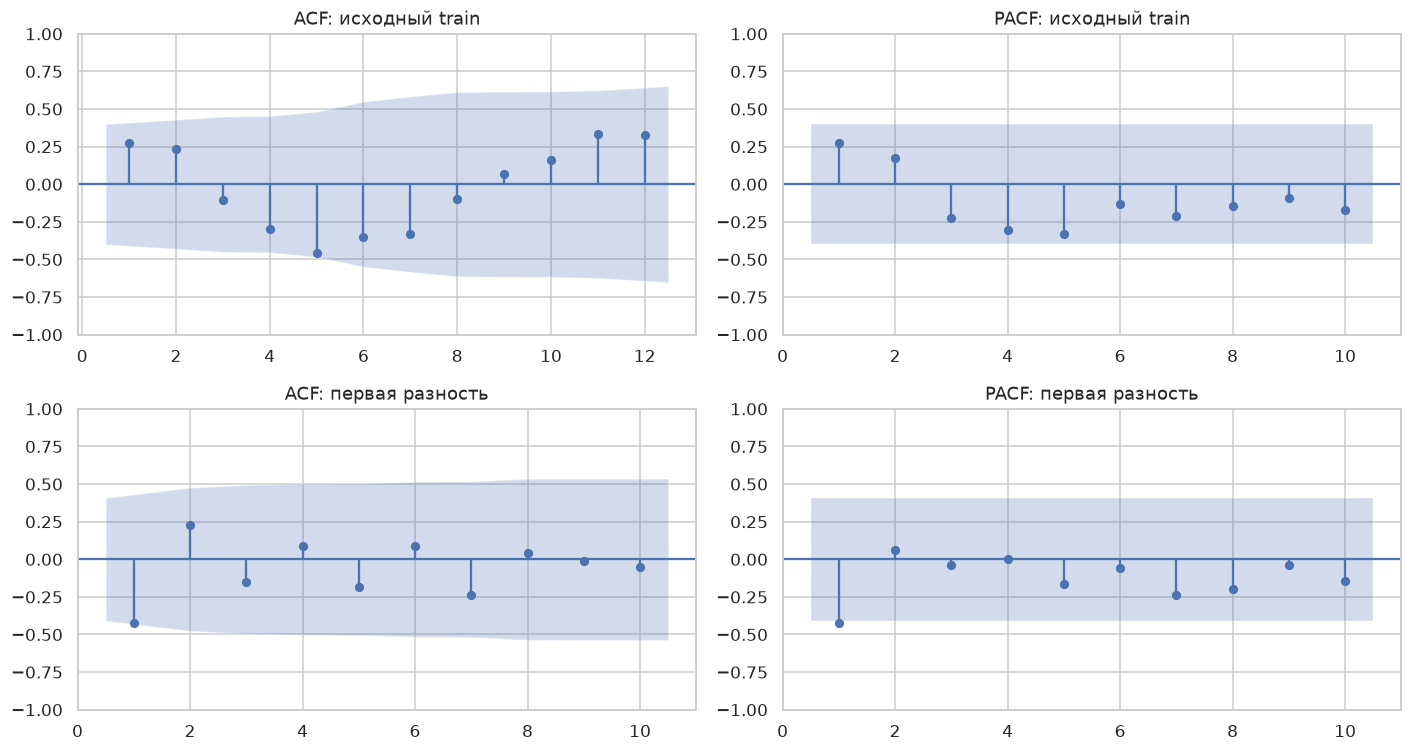

In [38]:
stationarity_rows = []
for name, series in {
    'Исходный train': y_eda,
    'Первая разность': y_eda.diff().dropna(),
    'Сезонная разность (12)': y_eda.diff(12).dropna(),
}.items():
    # На короткой выборке используем до трёх лагов ADF
    adf = adfuller(series, regression='c', maxlag=3, autolag='AIC', result_object=True)
    # Границу табличного p-value KPSS показываем в таблице вместо предупреждения.
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', InterpolationWarning)
        kpss_result = kpss(series, regression='c', nlags='auto', result_object=True)
    stationarity_rows.append({
        'Ряд': name, 'n': len(series), 'ADF p-value': adf.pvalue,
        'KPSS p-value': kpss_result.pvalue, 'Лаги ADF': adf.lags,
    })
stationarity_table = pd.DataFrame(stationarity_rows).set_index('Ряд')
stationarity_display = stationarity_table.copy()
stationarity_display['KPSS p-value'] = stationarity_table['KPSS p-value'].map(
    lambda p: '> 0.100' if p == 0.1 else '< 0.010' if p == 0.01 else f'{p:.3f}'
)
display(stationarity_display)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
plot_acf(y_eda, lags=12, ax=axes[0, 0], zero=False)
plot_pacf(y_eda, lags=10, ax=axes[0, 1], zero=False, method='ywm')
plot_acf(y_eda.diff().dropna(), lags=10, ax=axes[1, 0], zero=False)
plot_pacf(y_eda.diff().dropna(), lags=10, ax=axes[1, 1], zero=False, method='ywm')
for ax, title in zip(axes.flat, ['ACF: исходный train', 'PACF: исходный train',
                                'ACF: первая разность', 'PACF: первая разность']):
    ax.set_title(title)
fig.tight_layout()
plt.show()

### Сетка, признаки и правило выбора

- **ARIMA:** `p, q ∈ {0, 1, 2}`, `d ∈ {0, 1}`. При `d=0` задаём константу
  и линейный тренд, при `d=1` — дрейф.
- **SARIMAX, D=0:** обычные порядки `(0,0,0)`, `(1,0,0)`, `(0,0,1)`, `(1,0,1)`;
  сезонные `(1,0,0,12)` или `(0,0,1,12)`; признаки `Promotion`, `HolidayMonth` и время.
- **SARIMAX, D=1:** обычный порядок `(0,0,0)` или `(1,0,0)`;
  сезонный `(0,1,0,12)` или `(0,1,1,12)`; константа и `Promotion`.
  Сезонная разность обнуляет `HolidayMonth`, а разность времени совпадает с константой,
  поэтому эти регрессоры исключаем.

В каждом семействе выбираем минимум MSE на validation, при равенстве — меньшее число параметров.
Затем сравниваем семейства по тому же правилу. Обучение ведём в тысячах денежных единиц,
прогнозы и ошибки переводим обратно. План акций для validation/test считаем известным заранее.

In [39]:
SCALE = 1000.0


def make_exog(frame, seasonal_d):
    """Календарные признаки и план акций для SARIMAX."""
    x = frame[['Promotion']].astype(float).copy()
    if seasonal_d == 0:
        x['HolidayMonth'] = frame['HolidayMonth'].astype(float)
        # Время в годах с общей точкой отсчёта для всех выборок
        x['time'] = (frame.index.year - 2020) + (frame.index.month - 1) / 12
    return x


def fit_model(spec, frame):
    """Обучение ARIMA или SARIMAX на продажах в тысячах денежных единиц."""
    with warnings.catch_warnings():
        warnings.filterwarnings(
            'ignore',
            message=(
                r'Non-stationary starting autoregressive parameters found\..*|'
                r'Non-invertible starting MA parameters found\..*|'
                r'Too few observations to estimate starting parameters for seasonal ARMA\..*'
            ),
            category=EstimationWarning,
        )
        y = frame['SalesAmount'].astype(float) / SCALE
        if spec['family'] == 'ARIMA':
            model = ARIMA(y, order=spec['order'],
                          trend='ct' if spec['order'][1] == 0 else 't')
            return model.fit(method_kwargs={'maxiter': 300})
        exog = make_exog(frame, spec['seasonal_order'][1])
        model = SARIMAX(y, exog=exog, order=spec['order'],
                        seasonal_order=spec['seasonal_order'], trend='c',
                        enforce_stationarity=True, enforce_invertibility=True)
        return model.fit(disp=False, maxiter=300)

def forecast_model(fitted, spec, future_frame):
    """Прогноз продаж и 95% прогнозный интервал."""
    if spec['family'] == 'SARIMAX':
        exog = make_exog(future_frame, spec['seasonal_order'][1])
        forecast = fitted.get_forecast(steps=len(future_frame), exog=exog)
    else:
        forecast = fitted.get_forecast(steps=len(future_frame))
    return forecast.predicted_mean * SCALE, forecast.conf_int(alpha=0.05) * SCALE


def seasonal_naive(history, future_index):
    """Базовый прогноз: продажи соответствующих месяцев последнего года."""
    last_year = history.iloc[-12:].to_numpy()
    return pd.Series(last_year[:len(future_index)], index=future_index)


def forecast_metrics(actual, predicted):
    """Метрики прогноза в исходных денежных единицах."""
    mse = mean_squared_error(actual, predicted)
    return {'MSE': mse, 'RMSE': np.sqrt(mse), 'R²': r2_score(actual, predicted),
            'NRMSE, %': 100 * np.sqrt(mse) / actual.mean()}


specs = []
for p, d, q in product(range(3), [0, 1], range(3)):
    specs.append({'family': 'ARIMA', 'order': (p, d, q),
                  'seasonal_order': (0, 0, 0, 0)})
for order, seasonal_order in product(
    [(0, 0, 0), (1, 0, 0), (0, 0, 1), (1, 0, 1)],
    [(1, 0, 0, 12), (0, 0, 1, 12)],
):
    specs.append({'family': 'SARIMAX', 'order': order,
                  'seasonal_order': seasonal_order})
for order, seasonal_order in product(
    [(0, 0, 0), (1, 0, 0)], [(0, 1, 0, 12), (0, 1, 1, 12)],
):
    specs.append({'family': 'SARIMAX', 'order': order,
                  'seasonal_order': seasonal_order})

# Сравниваем порядки моделей по ошибке validation и информационным критериям
search_rows, validation_predictions = [], {}
for candidate_id, spec in enumerate(specs):
    fitted = fit_model(spec, train)
    mean, _ = forecast_model(fitted, spec, validation)
    metrics = forecast_metrics(validation['SalesAmount'], mean)
    search_rows.append({
        'id': candidate_id, **spec,
        'AIC': fitted.aic, 'BIC': fitted.bic, 'Параметров': len(fitted.params),
        'n_eff': fitted.nobs_effective,
        'Группа IC (d,D)': str((spec['order'][1], spec['seasonal_order'][1])),
        **{f'val {key}': value for key, value in metrics.items()},
    })
    validation_predictions[candidate_id] = mean

search_table = pd.DataFrame(search_rows).set_index('id')
selected_ids = {
    family: int(group.sort_values(['val MSE', 'Параметров']).index[0])
    for family, group in search_table.groupby('family')
}
selected_specs = {family: specs[candidate_id] for family, candidate_id in selected_ids.items()}
validation_scores = search_table.loc[list(selected_ids.values())].copy()
display(search_table.sort_values('val MSE')[
    ['family', 'order', 'seasonal_order', 'val MSE', 'val R²', 'AIC', 'BIC', 'n_eff']
].head(12))

,family,order,seasonal_order,val MSE,val R²,AIC,BIC,n_eff
id,,,,,,,,
29,SARIMAX,"(1, 0, 0)","(0, 1, 1, 12)","1,031,080.752",0.833,38.003,40.428,12
27,SARIMAX,"(0, 0, 0)","(0, 1, 1, 12)","1,089,158.310",0.824,36.409,38.348,12
26,SARIMAX,"(0, 0, 0)","(0, 1, 0, 12)","1,089,159.244",0.824,34.409,35.864,12
28,SARIMAX,"(1, 0, 0)","(0, 1, 0, 12)","1,108,826.893",0.821,36.018,37.957,12
18,SARIMAX,"(0, 0, 0)","(1, 0, 0, 12)","1,268,237.050",0.795,87.452,94.520,24
20,SARIMAX,"(1, 0, 0)","(1, 0, 0, 12)","1,331,058.050",0.785,86.879,95.125,24
24,SARIMAX,"(1, 0, 1)","(1, 0, 0, 12)","1,654,655.202",0.732,82.999,92.423,24
22,SARIMAX,"(0, 0, 1)","(1, 0, 0, 12)","2,112,154.832",0.658,81.215,89.461,24
21,SARIMAX,"(1, 0, 0)","(0, 0, 1, 12)","2,711,153.637",0.561,89.140,97.386,24


In [40]:
# Выбор семейства фиксируется до доступа к фактическим продажам test
winner_id = int(validation_scores.sort_values(['val MSE', 'Параметров']).index[0])
preferred_family = specs[winner_id]['family']
preferred_spec = specs[winner_id]
val_naive = seasonal_naive(train['SalesAmount'], validation.index)
val_best = validation_predictions[winner_id]

# Порог установлен заранее: RMSE / средние фактические продажи <= 20%
# R² > 0, MSE не выше сезонного наивного прогноза
# Оценивается среднее качество всех первых h месяцев
MAX_NRMSE = 20.0
horizon_rows = []
for horizon in range(3, len(validation) + 1):
    actual = validation['SalesAmount'].iloc[:horizon]
    score = forecast_metrics(actual, val_best.iloc[:horizon])
    naive_mse = mean_squared_error(actual, val_naive.iloc[:horizon])
    acceptable = score['NRMSE, %'] <= MAX_NRMSE and score['R²'] > 0 and score['MSE'] <= naive_mse
    horizon_rows.append({'h, месяцев': horizon, **score, 'MSE seasonal naive': naive_mse,
                         'Приемлемо на validation': acceptable})
validation_horizons = pd.DataFrame(horizon_rows).set_index('h, месяцев')
acceptable_horizons = validation_horizons.index[validation_horizons['Приемлемо на validation']]
chosen_horizon = int(acceptable_horizons.max())
display(validation_scores[['family', 'order', 'seasonal_order',
                           'val MSE', 'val R²', 'AIC', 'BIC']])
display(validation_horizons)
print('Выбрано семейство:', preferred_family)
print('Зафиксированный горизонт:', chosen_horizon, 'месяцев')

,family,order,seasonal_order,val MSE,val R²,AIC,BIC
id,,,,,,,
14,ARIMA,"(2, 0, 2)","(0, 0, 0, 0)","3,855,233.251",0.376,97.898,106.144
29,SARIMAX,"(1, 0, 0)","(0, 1, 1, 12)","1,031,080.752",0.833,38.003,40.428


,MSE,RMSE,R²,"NRMSE, %",MSE seasonal naive,Приемлемо на validation
"h, месяцев",,,,,,
3,"1,418,569.715","1,191.037",0.359,8.124,"6,206,240.667",True
4,"1,111,697.090","1,054.370",0.681,7.596,"4,940,370.750",True
5,"1,057,517.661","1,028.357",0.847,7.994,"4,389,784.800",True
6,"1,006,166.985","1,003.079",0.884,8.291,"3,672,855.500",True
7,"876,383.521",936.154,0.897,8.012,"3,229,378.429",True
8,"1,203,168.175","1,096.890",0.838,9.352,"3,448,992.250",True
9,"1,099,806.070","1,048.716",0.834,8.927,"3,067,917.667",True
10,"990,686.141",995.332,0.834,8.518,"2,764,511.500",True
11,"1,052,438.394","1,025.884",0.807,8.771,"2,600,145.364",True


Выбрано семейство: SARIMAX
Зафиксированный горизонт: 12 месяцев


In [41]:
arima_spec = selected_specs['ARIMA']
sarimax_spec = selected_specs['SARIMAX']
display(Markdown(f"""
### Выводы по этапу 3

У исходного train ADF p-value = **{stationarity_table.loc['Исходный train', 'ADF p-value']:.3f}**,
KPSS p-value > **{stationarity_table.loc['Исходный train', 'KPSS p-value']:.3f}**.
Единичный корень отвергается, стационарность вокруг константы не отвергается,
поэтому рассматриваем `d=0`. `D=1` проверяем как прогнозную альтернативу:
тесты сезонной разности не подтверждают её стационарность.

По validation выбраны **ARIMA{arima_spec['order']}** и
**SARIMAX{sarimax_spec['order']} × {sarimax_spec['seasonal_order']}**.
Предпочтительна **{preferred_family}**:
MSE = **{validation_scores.loc[winner_id, 'val MSE']:,.0f}** ден. ед.²,
R² = **{validation_scores.loc[winner_id, 'val R²']:.3f}**.
Горизонт по принятому правилу - **{chosen_horizon} месяцев**.
"""))


### Выводы по этапу 3

У исходного train ADF p-value = **0.027**,
KPSS p-value > **0.100**.
Единичный корень отвергается, стационарность вокруг константы не отвергается,
поэтому рассматриваем `d=0`. `D=1` проверяем как прогнозную альтернативу:
тесты сезонной разности не подтверждают её стационарность.

По validation выбраны **ARIMA(2, 0, 2)** и
**SARIMAX(1, 0, 0) × (0, 1, 1, 12)**.
Предпочтительна **SARIMAX**:
MSE = **1,031,081** ден. ед.²,
R² = **0.833**.
Горизонт по принятому правилу - **12 месяцев**.


## 4. Качество моделей, AIC/BIC и остатки

Переоцениваем коэффициенты выбранных моделей на 36 месяцах (2020–2022), затем
однократно прогнозируем все 12 месяцев 2023 года. Внутри этого горизонта модель
не получает фактических продаж 2023 года. Добавляем **seasonal naive** как
ориентир: сравнение только двух сложных моделей может скрыть слабый прогноз.

$$MSE=\frac{1}{n}\sum_{t=1}^{n}(y_t-\hat y_t)^2, \qquad
R^2=1-\frac{\sum(y_t-\hat y_t)^2}{\sum(y_t-\bar y)^2}.$$

MSE измеряется в ден. ед.², RMSE - в ден. ед.; чем меньше, тем лучше.
R² может быть отрицательным; это означает результат хуже постоянного среднего
оцениваемого отрезка. На временных рядах R² дополняет MSE, а не заменяет его.

In [42]:
# Оцениваем прогноз выбранных моделей на отложенном 2023 году
development = pd.concat([train, validation]).asfreq('MS')
final_fits, test_predictions, test_intervals, test_rows = {}, {}, {}, []
for family, spec in selected_specs.items():
    fitted = fit_model(spec, development)
    final_fits[family] = fitted
    mean, interval = forecast_model(fitted, spec, test)
    test_predictions[family], test_intervals[family] = mean, interval
    row = {'Модель': family, 'Порядок': str(spec['order']),
           'Сезонный порядок': str(spec['seasonal_order']),
           **forecast_metrics(test['SalesAmount'], mean),
           'AIC': fitted.aic, 'BIC': fitted.bic, 'Параметров': len(fitted.params),
           'n_eff': fitted.nobs_effective,
           'Группа IC (d,D)': str((spec['order'][1], spec['seasonal_order'][1])),
           'Покрытие 95% интервала, %': 100 * np.mean(
               (test['SalesAmount'] >= interval.iloc[:, 0]) &
               (test['SalesAmount'] <= interval.iloc[:, 1])),
           'Средняя ширина интервала': (interval.iloc[:, 1] - interval.iloc[:, 0]).mean(),
    }
    test_rows.append(row)

test_naive = seasonal_naive(development['SalesAmount'], test.index)
test_predictions['Seasonal naive'] = test_naive
test_rows.append({'Модель': 'Seasonal naive', **forecast_metrics(test['SalesAmount'], test_naive)})
test_scores = pd.DataFrame(test_rows).set_index('Модель')
display(test_scores[['MSE', 'RMSE', 'R²', 'NRMSE, %', 'AIC', 'BIC', 'n_eff', 'Группа IC (d,D)',
                     'Покрытие 95% интервала, %', 'Средняя ширина интервала']])

test_forecasts = pd.DataFrame({'Факт': test['SalesAmount'], **test_predictions})
test_forecasts.index.name = 'Date'
for family, interval in test_intervals.items():
    test_forecasts[f'{family} lower95'] = interval.iloc[:, 0]
    test_forecasts[f'{family} upper95'] = interval.iloc[:, 1]
display(test_forecasts)

,MSE,RMSE,R²,"NRMSE, %",AIC,BIC,n_eff,"Группа IC (d,D)","Покрытие 95% интервала, %",Средняя ширина интервала
Модель,,,,,,,,,,
ARIMA,"2,831,975.136","1,682.847",0.388,13.421,142.064,153.149,36.000,"(0, 0)",91.667,"6,275.236"
SARIMAX,"505,534.834",711.010,0.891,5.671,61.885,67.775,24.000,"(0, 1)",91.667,"2,456.438"
Seasonal naive,"2,757,115.250","1,660.456",0.404,13.243,NaN,NaN,NaN,NaN,NaN,NaN


,Факт,ARIMA,SARIMAX,Seasonal naive,ARIMA lower95,ARIMA upper95,SARIMAX lower95,SARIMAX upper95
Date,,,,,,,,
2023-01-01,13904,"13,600.696","13,964.934",16623,"11,073.982","16,127.409","12,738.343","15,191.524"
2023-02-01,13901,"13,045.156","14,447.701",14336,"10,454.671","15,635.642","13,219.329","15,676.073"
2023-03-01,13534,"12,278.917","13,717.023",13023,"9,497.494","15,060.339","12,488.645","14,945.400"
2023-04-01,12048,"11,521.379","12,123.578",11537,"8,510.151","14,532.608","10,895.200","13,351.956"
2023-05-01,12949,"10,971.201","12,000.388",8800,"7,802.160","14,140.242","10,772.010","13,228.766"
2023-06-01,9104,"10,757.792","8,571.950",8273,"7,535.994","13,979.589","7,343.572","9,800.328"
2023-07-01,10042,"10,914.435","10,001.052",9199,"7,693.550","14,135.319","8,772.674","11,229.429"
2023-08-01,11566,"11,377.988","11,807.774",12043,"8,131.298","14,624.679","10,579.396","13,036.151"
2023-09-01,11759,"12,013.012","12,552.415",11892,"8,678.624","15,347.401","11,324.037","13,780.792"


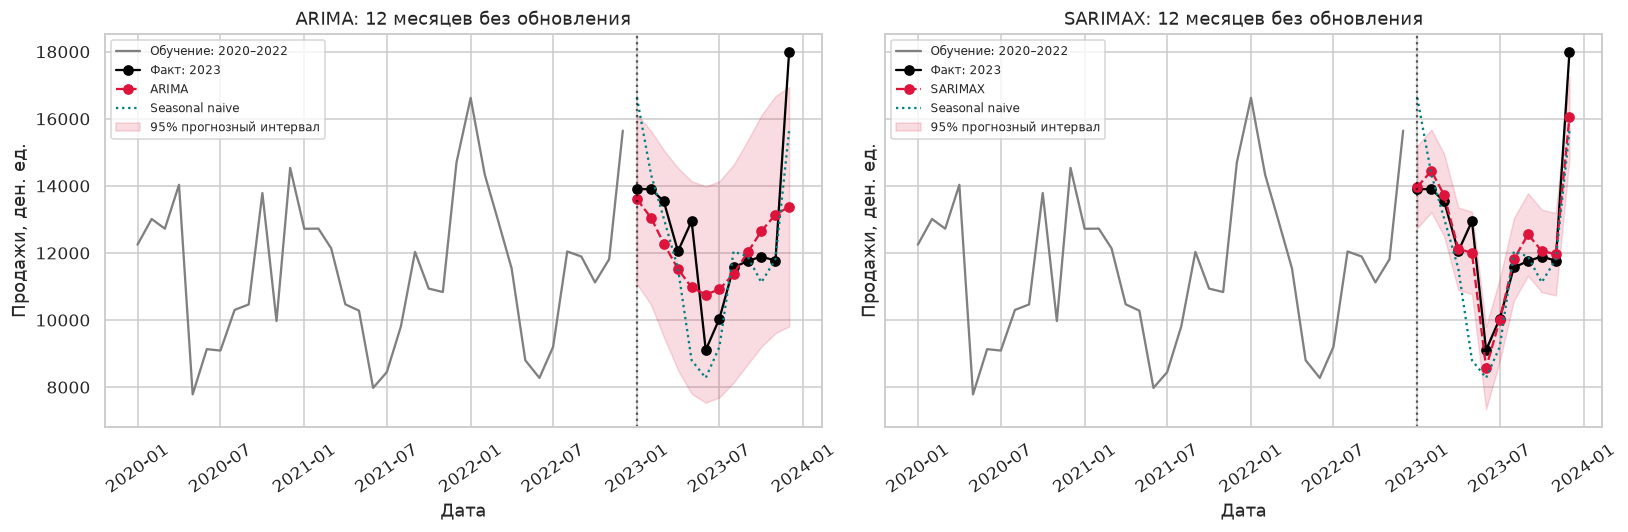

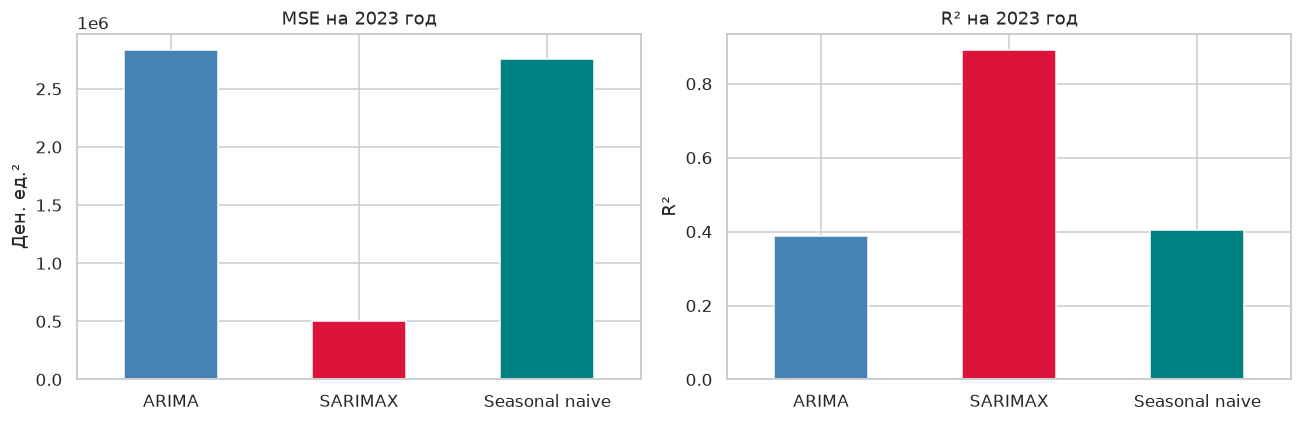

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, family in zip(axes, ['ARIMA', 'SARIMAX']):
    mean, interval = test_predictions[family], test_intervals[family]
    ax.plot(development['SalesAmount'], color='gray', label='Обучение: 2020–2022')
    ax.plot(test['SalesAmount'], marker='o', color='black', label='Факт: 2023')
    ax.plot(mean, marker='o', linestyle='--', color='crimson', label=family)
    ax.plot(test_naive, linestyle=':', color='teal', label='Seasonal naive')
    ax.fill_between(test.index, interval.iloc[:, 0], interval.iloc[:, 1],
                    color='crimson', alpha=0.15, label='95% прогнозный интервал')
    ax.axvline(test.index.min(), color='black', linestyle=':', alpha=0.6)
    ax.set(title=f'{family}: 12 месяцев без обновления', xlabel='Дата', ylabel='Продажи, ден. ед.')
    ax.tick_params(axis='x', rotation=35)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_scores['MSE'].plot.bar(ax=axes[0], color=['steelblue', 'crimson', 'teal'])
test_scores['R²'].plot.bar(ax=axes[1], color=['steelblue', 'crimson', 'teal'])
axes[0].set(title='MSE на 2023 год', ylabel='Ден. ед.²', xlabel='')
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(title='R² на 2023 год', ylabel='R²', xlabel='')
for ax in axes:
    ax.tick_params(axis='x', rotation=0)
fig.tight_layout()
plt.show()

### Сравнение по AIC и BIC

$$AIC=-2\log L+2k,\qquad BIC=-2\log L+k\log n_{eff}.$$

Меньшие значения предпочтительнее. Сравниваем кандидатов внутри одного семейства
и одинаковой группы разностей `(d,D)`, чтобы сохранить сопоставимость правдоподобий.
Таблица ниже относится к обучению на 24 месяцах; критерии итоговых моделей выше — к 36 месяцам.
Между выбранными ARIMA и SARIMAX с разными разностями сравниваем прежде всего MSE/R².

In [44]:
# Сравниваем AIC и BIC при одинаковых разностях
ic_rows = []
for (family, group), candidates in search_table.groupby(['family', 'Группа IC (d,D)']):
    for criterion in ['AIC', 'BIC']:
        candidate_id = int(candidates[criterion].idxmin())
        row = search_table.loc[candidate_id]
        ic_rows.append({'Семейство': family, 'Группа (d,D)': group,
                        'Критерий': criterion, 'id': candidate_id,
                        'Порядок': str(row['order']), 'Сезонный': str(row['seasonal_order']),
                        'Значение': row[criterion],
                        'val MSE': row['val MSE']})
ic_comparison = pd.DataFrame(ic_rows)
display(ic_comparison)

,Семейство,"Группа (d,D)",Критерий,id,Порядок,Сезонный,Значение,val MSE
0,ARIMA,"(0, 0)",AIC,14,"(2, 0, 2)","(0, 0, 0, 0)",97.898,"3,855,233.251"
1,ARIMA,"(0, 0)",BIC,14,"(2, 0, 2)","(0, 0, 0, 0)",106.144,"3,855,233.251"
2,ARIMA,"(1, 0)",AIC,9,"(1, 1, 0)","(0, 0, 0, 0)",105.376,"9,704,952.561"
3,ARIMA,"(1, 0)",BIC,9,"(1, 1, 0)","(0, 0, 0, 0)",108.782,"9,704,952.561"
4,SARIMAX,"(0, 0)",AIC,22,"(0, 0, 1)","(1, 0, 0, 12)",81.215,"2,112,154.832"
5,SARIMAX,"(0, 0)",BIC,22,"(0, 0, 1)","(1, 0, 0, 12)",89.461,"2,112,154.832"
6,SARIMAX,"(0, 1)",AIC,26,"(0, 0, 0)","(0, 1, 0, 12)",34.409,"1,089,159.244"
7,SARIMAX,"(0, 1)",BIC,26,"(0, 0, 0)","(0, 1, 0, 12)",35.864,"1,089,159.244"


### Диагностика остатков

- **Нормальность:** Shapiro–Wilk, гистограмма и Q–Q-график.
- **Автокорреляция:** Ljung–Box на лагах 6 и 12, ACF.
- **Гомоскедастичность:** Breusch–Pagan относительно времени и предсказанного уровня.

Используем стандартизованные одношаговые ошибки моделей на 36 месяцах,
исключив начальную диффузную инициализацию. В Ljung–Box учитываем число AR/MA-параметров
через `model_df`. Уровень значимости — 0.05; большее p-value означает, что гипотеза не отвергается.

,n остатков,Исключено в начале,Shapiro p,Ljung–Box(6) p,Ljung–Box(12) p,model_df,Breusch–Pagan p
Модель,,,,,,,
ARIMA,36,0,0.381,0.538,0.459,4,0.118
SARIMAX,24,12,0.334,0.311,0.769,2,0.050


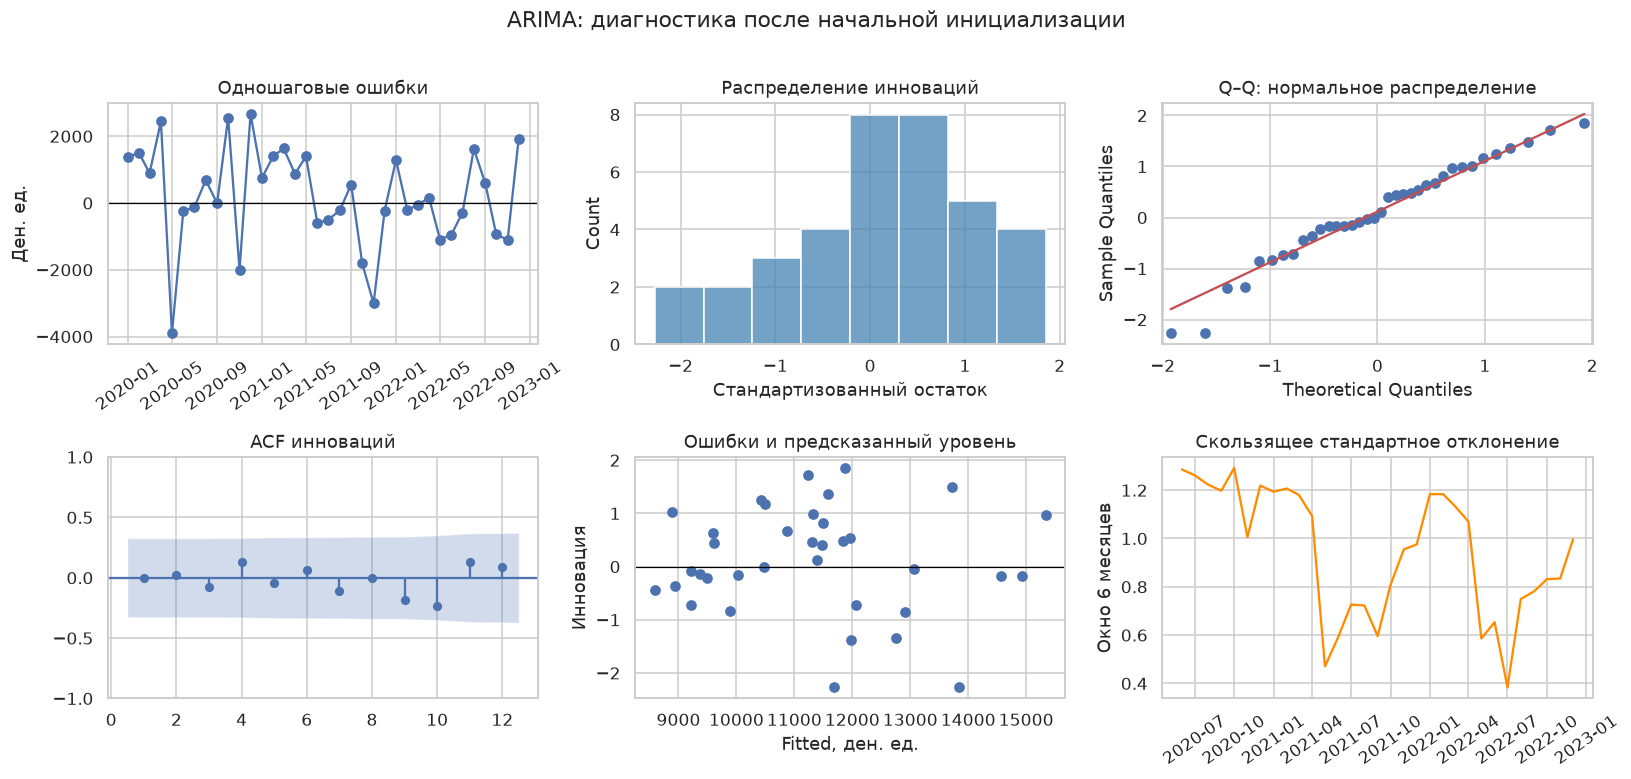

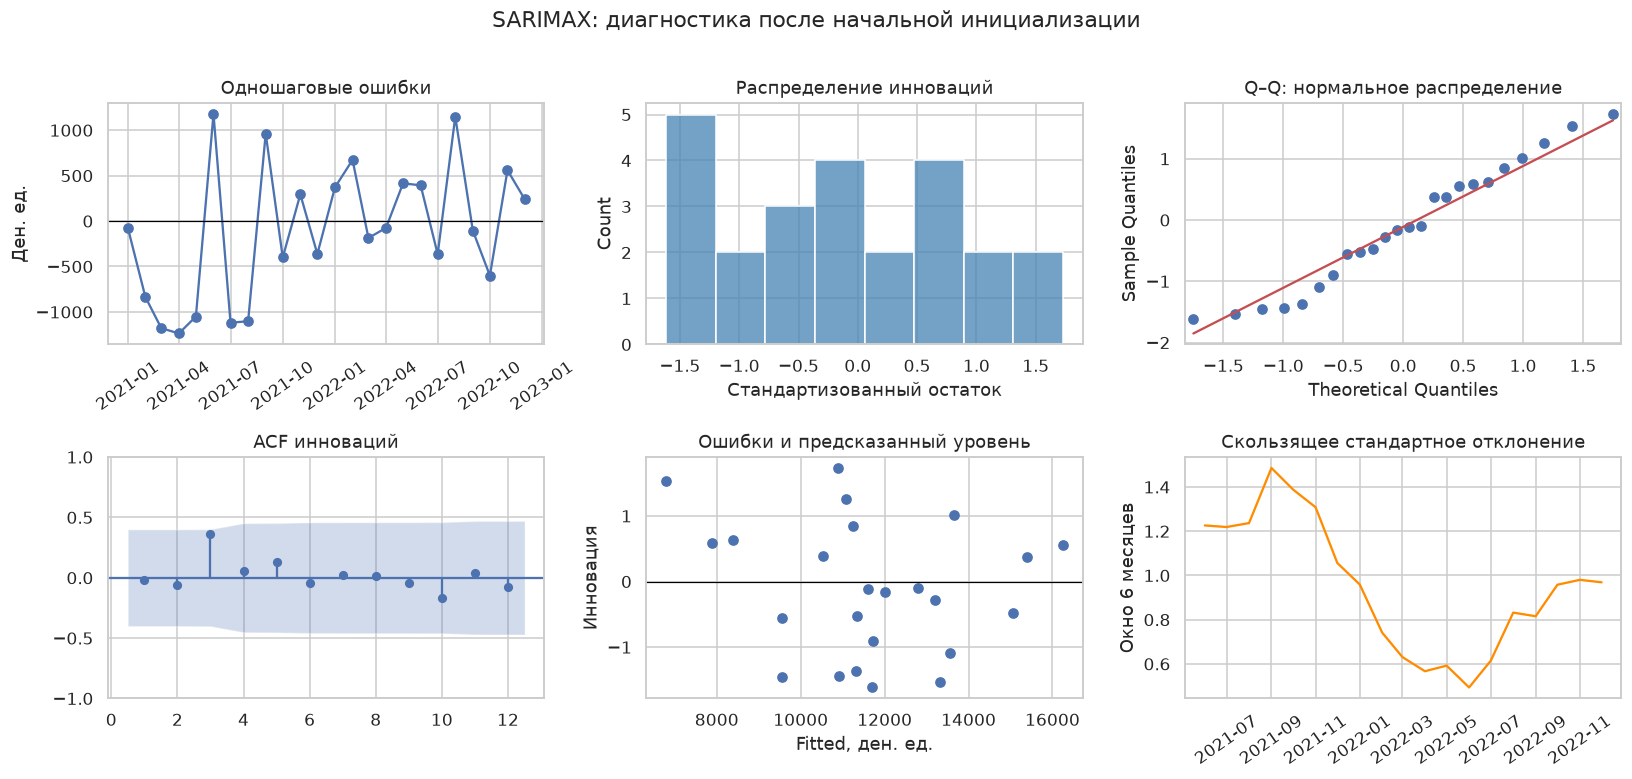

In [45]:
# Проверяем нормальность, автокорреляцию и постоянство дисперсии остатков.
diagnostic_rows, residual_frames = [], {}
for family, fitted in final_fits.items():
    spec = selected_specs[family]
    burn = max(int(fitted.loglikelihood_burn), int(fitted.filter_results.nobs_diffuse))
    index = development.index[burn:]
    standardized = pd.Series(
        np.asarray(fitted.filter_results.standardized_forecasts_error)[0, burn:], index=index,
    )
    raw_errors = pd.Series(np.asarray(fitted.resid)[burn:] * SCALE, index=index)
    fitted_values = pd.Series(np.asarray(fitted.fittedvalues)[burn:] * SCALE, index=index)
    ar_ma_df = spec['order'][0] + spec['order'][2] + spec['seasonal_order'][0] + spec['seasonal_order'][2]
    lb = acorr_ljungbox(standardized, lags=[6, 12], model_df=ar_ma_df, return_df=True)
    shapiro = stats.shapiro(standardized)
    variance_regressors = sm.add_constant(np.column_stack([
        np.arange(len(standardized)), fitted_values.to_numpy(),
    ]))
    bp = het_breuschpagan(standardized.to_numpy(), variance_regressors, robust=True)
    diagnostic_rows.append({
        'Модель': family, 'n остатков': len(standardized), 'Исключено в начале': burn,
        'Shapiro p': shapiro.pvalue,
        'Ljung–Box(6) p': lb.loc[6, 'lb_pvalue'], 'Ljung–Box(12) p': lb.loc[12, 'lb_pvalue'],
        'model_df': ar_ma_df, 'Breusch–Pagan p': bp[1],
    })
    residual_frames[family] = pd.DataFrame({
        'Остаток, ден. ед.': raw_errors, 'Стандартизованный остаток': standardized,
        'Fitted, ден. ед.': fitted_values,
    })

diagnostics = pd.DataFrame(diagnostic_rows).set_index('Модель')
display(diagnostics)

for family, residual_frame in residual_frames.items():
    e = residual_frame['Стандартизованный остаток']
    fig, axes = plt.subplots(2, 3, figsize=(15, 7))
    axes[0, 0].plot(residual_frame.index, residual_frame['Остаток, ден. ед.'], marker='o')
    axes[0, 0].axhline(0, color='black', linewidth=0.8)
    axes[0, 0].set(title='Одношаговые ошибки', ylabel='Ден. ед.')
    axes[0, 0].tick_params(axis='x', rotation=35)
    sns.histplot(e, bins=8, ax=axes[0, 1], color='steelblue')
    axes[0, 1].set(title='Распределение инноваций', xlabel='Стандартизованный остаток')
    sm.qqplot(e.to_numpy(), line='s', ax=axes[0, 2])
    axes[0, 2].set_title('Q–Q: нормальное распределение')
    plot_acf(e, lags=12, zero=False, ax=axes[1, 0])
    axes[1, 0].set_title('ACF инноваций')
    axes[1, 1].scatter(residual_frame['Fitted, ден. ед.'], e)
    axes[1, 1].axhline(0, color='black', linewidth=0.8)
    axes[1, 1].set(title='Ошибки и предсказанный уровень', xlabel='Fitted, ден. ед.', ylabel='Инновация')
    axes[1, 2].plot(e.index, e.rolling(6).std(), color='darkorange')
    axes[1, 2].set(title='Скользящее стандартное отклонение', ylabel='Окно 6 месяцев')
    axes[1, 2].tick_params(axis='x', rotation=35)
    fig.suptitle(f'{family}: диагностика после начальной инициализации', y=1.01)
    fig.tight_layout()
    plt.show()

In [46]:
test_leader = test_scores['MSE'].idxmin()
diagnostic_notes = []
for family, row in diagnostics.iterrows():
    normality = ('нормальность отвергается' if row['Shapiro p'] < 0.05
                 else 'нормальность не отвергается')
    autocorrelation = ('есть признаки автокорреляции' if min(row['Ljung–Box(6) p'], row['Ljung–Box(12) p']) < 0.05
                       else 'автокорреляция не выявлена')
    variance = ('есть признаки непостоянной дисперсии' if row['Breusch–Pagan p'] < 0.05
                else 'непостоянная дисперсия не выявлена')
    diagnostic_notes.append(f'- **{family}:** {normality}; {autocorrelation}; {variance}.')
display(Markdown(f"""
### Выводы по этапу 4

Минимум MSE на test у **{test_leader}**. Для выбранной по validation модели **{preferred_family}**:
MSE = **{test_scores.loc[preferred_family, 'MSE']:,.0f}**,
RMSE = **{test_scores.loc[preferred_family, 'RMSE']:,.0f}** ден. ед.,
R² = **{test_scores.loc[preferred_family, 'R²']:.3f}**.
MSE сезонного наивного прогноза - **{test_scores.loc['Seasonal naive', 'MSE']:,.0f}**.

{chr(10).join(diagnostic_notes)}

У SARIMAX Breusch–Pagan p-value = **{diagnostics.loc['SARIMAX', 'Breusch–Pagan p']:.4f}**,
близко к границе 0.05: признак непостоянной дисперсии пограничный.
"""))


### Выводы по этапу 4

Минимум MSE на test у **SARIMAX**. Для выбранной по validation модели **SARIMAX**:
MSE = **505,535**,
RMSE = **711** ден. ед.,
R² = **0.891**.
MSE сезонного наивного прогноза - **2,757,115**.

- **ARIMA:** нормальность не отвергается; автокорреляция не выявлена; непостоянная дисперсия не выявлена.
- **SARIMAX:** нормальность не отвергается; автокорреляция не выявлена; есть признаки непостоянной дисперсии.

У SARIMAX Breusch–Pagan p-value = **0.0497**,
близко к границе 0.05: признак непостоянной дисперсии пограничный.


## 5. Горизонт прогноза и итоговая интерпретация

Рабочий критерий приемлемого качества: **NRMSE ≤ 20%, R² > 0 и MSE ≤ MSE seasonal naive**.
Порог 20% принят для задачи, поскольку бизнес-критерий не задан.
Выбранный по validation горизонт проверяем на test; при этом разбиении доступно до 12 месяцев.

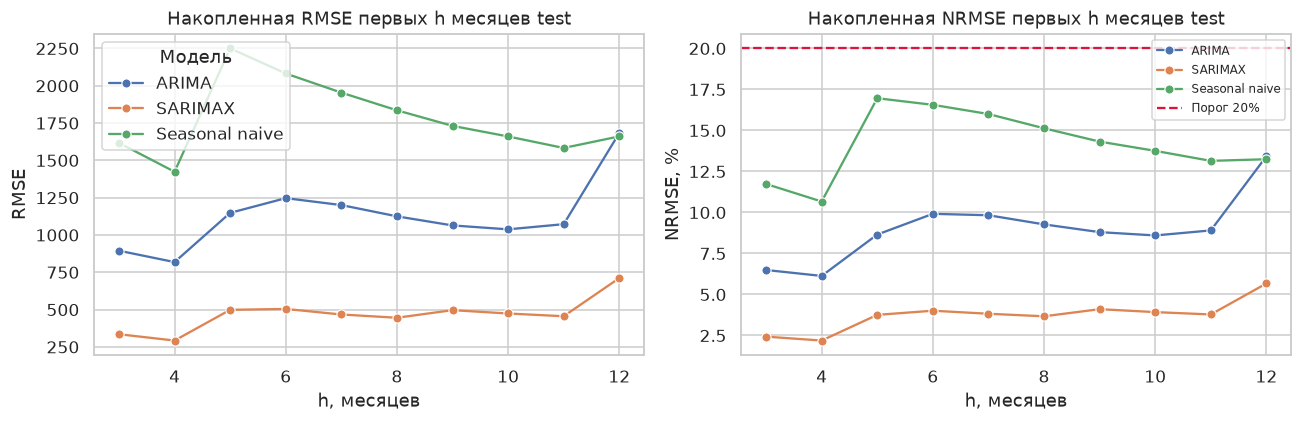

,Модель,Зафиксированный h,MSE,RMSE,R²,"NRMSE, %",MSE seasonal naive,Правило подтверждено на test
0,SARIMAX,12,"505,534.834",711.010,0.891,5.671,"2,757,115.250",True


In [47]:
test_horizon_rows = []
for family, mean in test_predictions.items():
    for horizon in range(3, len(test) + 1):
        score = forecast_metrics(test['SalesAmount'].iloc[:horizon], mean.iloc[:horizon])
        test_horizon_rows.append({'Модель': family, 'h, месяцев': horizon, **score})
test_horizons = pd.DataFrame(test_horizon_rows)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.lineplot(data=test_horizons, x='h, месяцев', y='RMSE', hue='Модель', marker='o', ax=axes[0])
sns.lineplot(data=test_horizons, x='h, месяцев', y='NRMSE, %', hue='Модель', marker='o', ax=axes[1])
axes[1].axhline(MAX_NRMSE, color='crimson', linestyle='--', label='Порог 20%')
axes[1].legend(fontsize=8)
axes[0].set_title('Накопленная RMSE первых h месяцев test')
axes[1].set_title('Накопленная NRMSE первых h месяцев test')
fig.tight_layout()
plt.show()

fixed_horizon_score = forecast_metrics(
    test['SalesAmount'].iloc[:chosen_horizon],
    test_predictions[preferred_family].iloc[:chosen_horizon],
)
fixed_naive_mse = mean_squared_error(
    test['SalesAmount'].iloc[:chosen_horizon], test_naive.iloc[:chosen_horizon],
)
test_confirmed = (fixed_horizon_score['NRMSE, %'] <= MAX_NRMSE
                  and fixed_horizon_score['R²'] > 0
                  and fixed_horizon_score['MSE'] <= fixed_naive_mse)
display(pd.DataFrame([{
    'Модель': preferred_family, 'Зафиксированный h': chosen_horizon,
    **fixed_horizon_score, 'MSE seasonal naive': fixed_naive_mse,
    'Правило подтверждено на test': test_confirmed,
}]))

,Forecast,Lower95,Upper95,Promotion_scenario,HolidayMonth
Date,,,,,
2024-01-01,"14,531.014","13,291.542","15,770.486",0,0
2024-02-01,"14,944.344","13,704.703","16,183.985",0,0
2024-03-01,"14,304.568","13,064.927","15,544.209",0,0
2024-04-01,"12,708.021","11,468.381","13,947.662",0,0
2024-05-01,"9,876.517","8,636.876","11,116.158",0,0
2024-06-01,"9,308.340","8,068.699","10,547.981",0,0
2024-07-01,"10,644.585","9,404.944","11,884.226",0,0
2024-08-01,"12,380.613","11,140.972","13,620.254",0,0
2024-09-01,"12,987.310","11,747.669","14,226.951",0,0


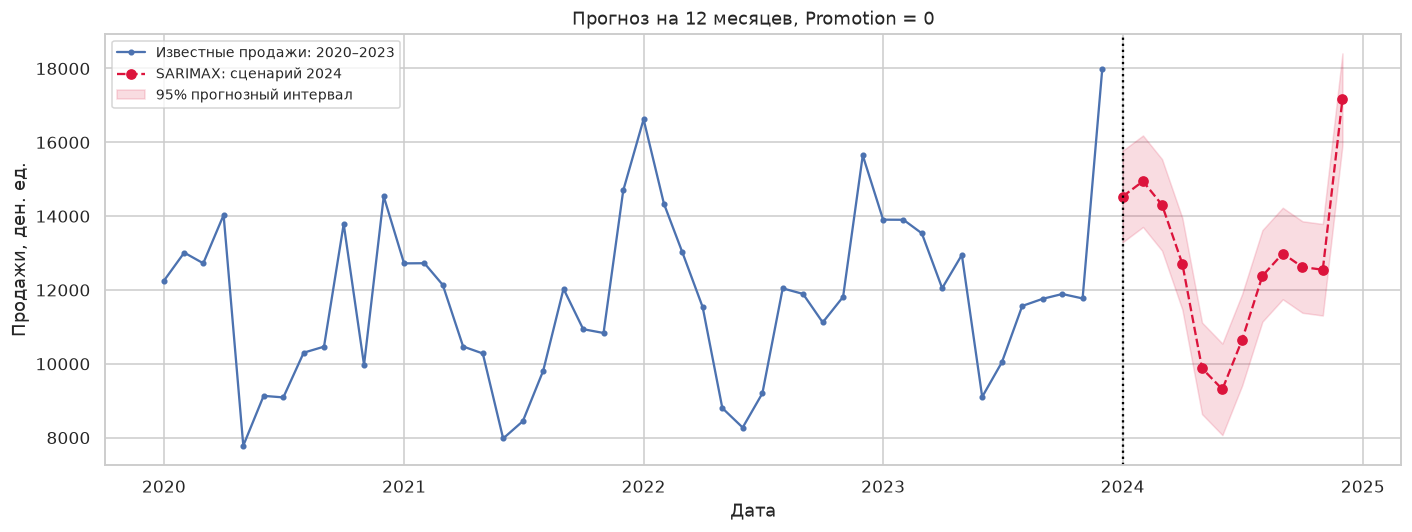


### Выводы по этапу 5

Для **SARIMAX** приемлемое качество на горизонте **12 месяцев**
**подтверждено** на test.
Финальная модель обучена на всех 48 наблюдениях; прогноз охватывает
**01.2024 - 12.2024** при `Promotion = 0`.
При изменении плана акций прогноз нужно пересчитать. Его будущая точность пока неизвестна.


In [48]:
# Финальная модель обучается на всех 48 известных месяцах
future_dates = pd.date_range(df.index.max() + pd.offsets.MonthBegin(1),
                             periods=chosen_horizon, freq='MS', name='Date')
# Сценарий 2024 года: Promotion = 0, праздничный месяц — декабрь
future_frame = pd.DataFrame({
    'Promotion': np.zeros(chosen_horizon, dtype=int),
    'HolidayMonth': (future_dates.month == 12).astype(int),
}, index=future_dates)
production_fit = fit_model(preferred_spec, df)
future_mean, future_interval = forecast_model(production_fit, preferred_spec, future_frame)
future_forecast = pd.DataFrame({
    'Forecast': future_mean, 'Lower95': future_interval.iloc[:, 0],
    'Upper95': future_interval.iloc[:, 1],
    'Promotion_scenario': future_frame['Promotion'],
    'HolidayMonth': future_frame['HolidayMonth'],
})
future_forecast.index.name = 'Date'
display(future_forecast)

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['SalesAmount'], marker='o', markersize=3, label='Известные продажи: 2020–2023')
ax.plot(future_mean, marker='o', linestyle='--', color='crimson', label=f'{preferred_family}: сценарий 2024')
ax.fill_between(future_dates, future_forecast['Lower95'], future_forecast['Upper95'],
                color='crimson', alpha=0.15, label='95% прогнозный интервал')
ax.axvline(future_dates.min(), color='black', linestyle=':')
ax.set(title=f'Прогноз на {chosen_horizon} месяцев, Promotion = 0',
       xlabel='Дата', ylabel='Продажи, ден. ед.')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
confirmation_note = ('подтверждено' if test_confirmed else 'не подтверждено')
display(Markdown(f"""
### Выводы по этапу 5

Для **{preferred_family}** приемлемое качество на горизонте **{chosen_horizon} месяцев**
**{confirmation_note}** на test.
Финальная модель обучена на всех 48 наблюдениях; прогноз охватывает
**{future_dates[0]:%m.%Y} - {future_dates[-1]:%m.%Y}** при `Promotion = 0`.
При изменении плана акций прогноз нужно пересчитать. Его будущая точность пока неизвестна.
"""))